In [3]:
# pandas is the tool for working with tables in Python. "pd" is its short name.
import pandas as pd

# opens the CSV and stores it as a table called df (short for dataframe)
# the file name must match exactly, and the file must be in the same folder as the notebook
# utf-8-sig removes a hidden character at the start of the file
df = pd.read_csv("greedy_uber_eats_100k_orders.csv", encoding="utf-8-sig")

# prints (rows, columns). Expect (100000, 36)
print(df.shape)

# prints the name of the first column. Expect Order_ID
print(df.columns[0])

# shows the first 5 rows, so you can see what the data looks like
df.head(5)

(100000, 36)
Order_ID


,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,City,Area,Restaurant,Cuisine,...,Distance_KM,Customer_Rating,Promo_Code,New_Customer,Device,Acquisition_Channel,Weather,Order_Hour,Meal_Period,Weekend
0,UE0000001,12/05/26,8:47,C14720,Simran Agarwal,18,Mumbai,Andheri,Bikanervala,North Indian,...,3.8,4.0,WEEKEND100,No,Android,Referral,Cloudy,8,Breakfast,No
1,UE0000002,19/09/25,8:24,C23088,Arjun Verma,32,Gurugram,Sector 48,Popeyes,Chicken,...,3.9,5.0,NaN,No,iOS,Organic,Cloudy,8,Breakfast,No
2,UE0000003,19/12/25,18:23,C18251,Nikhil Khan,21,Noida,Sector 62,WOW! Momo,Momos,...,3.3,NaN,NaN,No,Android,Organic,Cloudy,18,Dinner,No
3,UE0000004,17/03/26,21:20,C16172,Arjun Verma,25,Greater Noida,Dundahera,Starbucks,Cafe,...,4.9,4.0,SAVE50,No,Android,Organic,Clear,21,Dinner,No
4,UE0000005,24/10/25,18:29,C16636,Rohan Yadav,58,Chennai,Adyar,Barbeque Nation,North Indian,...,4.4,5.0,NaN,No,Android,YouTube Ad,Cloudy,18,Dinner,No


In [4]:
# Step 1: look at the table’s structure
# shows every column, its data type, and how many values are filled in
df.info

<bound method DataFrame.info of         Order_ID Order_Date Order_Time Customer_ID   Customer_Name  \
0      UE0000001   12/05/26       8:47      C14720  Simran Agarwal   
1      UE0000002   19/09/25       8:24      C23088     Arjun Verma   
2      UE0000003   19/12/25      18:23      C18251     Nikhil Khan   
3      UE0000004   17/03/26      21:20      C16172     Arjun Verma   
4      UE0000005   24/10/25      18:29      C16636     Rohan Yadav   
...          ...        ...        ...         ...             ...   
99995  UE0099996   27/05/25      10:45      C08212     Priya Kumar   
99996  UE0099997   25/08/26       8:09      C14806    Riya Agarwal   
99997  UE0099998   30/06/26       7:19      C16379    Rohan Mishra   
99998  UE0099999   25/01/26      19:01      C10037     Karan Mehta   
99999  UE0100000   04/06/25      10:28      C22821    Nikhil Verma   

       Customer_Age           City           Area       Restaurant  \
0                18         Mumbai        Andheri      Bi

In [5]:
# counts empty cells in each column
df.isna().sum

<bound method DataFrame.sum of        Order_ID  Order_Date  Order_Time  Customer_ID  Customer_Name  \
0         False       False       False        False          False   
1         False       False       False        False          False   
2         False       False       False        False          False   
3         False       False       False        False          False   
4         False       False       False        False          False   
...         ...         ...         ...          ...            ...   
99995     False       False       False        False          False   
99996     False       False       False        False          False   
99997     False       False       False        False          False   
99998     False       False       False        False          False   
99999     False       False       False        False          False   

       Customer_Age   City   Area  Restaurant  Cuisine  ...  Distance_KM  \
0             False  False  False       

In [6]:
# first number fully indentical rows 
# second number Order_ID repeated(an order counted twice)
print(df.duplicated().sum())
print(df["Order_ID"].duplicated().sum())

0
0


In [7]:
# making a copy so the original df stays untouched
df_clean = df.copy()

# turning the text dates (day/month/year) into real dates

df_clean["Order_Date"] = pd.to_datetime(df_clean["Order_Date"], format="%d/%m/%y")

# new column with year and month, for monthly trends later
df_clean["Order_Month"] = df_clean["Order_Date"].dt.strftime("%Y-%m")

# checking the result
print(df_clean["Order_Date"].dtype)
print(df_clean["Order_Date"].min(), df_clean["Order_Date"].max())
df_clean[["Order_Date", "Order_Month"]].head()

datetime64[us]
2025-01-01 00:00:00 2026-08-30 00:00:00


,Order_Date,Order_Month
0,2026-05-12,2026-05
1,2025-09-19,2025-09
2,2025-12-19,2025-12
3,2026-03-17,2026-03
4,2025-10-24,2025-10


In [8]:
# 1. does final value = gross - discount + packaging + delivery + tax?
calc = (df_clean["Gross_Value_INR"] - df_clean["Discount_INR"]
        + df_clean["Packaging_Fee_INR"] + df_clean["Delivery_Fee_INR"]
        + df_clean["Tax_INR"])
print("final value mismatches:", ((calc - df_clean["Final_Order_Value_INR"]).abs() > 0.05).sum())

# 2. does restaurant payout + platform revenue = final value?
split = df_clean["Restaurant_Payout_INR"] + df_clean["Platform_Revenue_INR"]
print("payout split mismatches:", ((split - df_clean["Final_Order_Value_INR"]).abs() > 0.05).sum())

# 3. does profit = platform revenue - cost?
prof = df_clean["Platform_Revenue_INR"] - df_clean["Estimated_Cost_INR"]
print("profit mismatches:", ((prof - df_clean["Estimated_Profit_INR"]).abs() > 0.05).sum())

# 4. how many orders lost money?
print("negative profit orders:", (df_clean["Estimated_Profit_INR"] < 0).sum())

# 5. which statuses have 0 delivery time?
print(df_clean[df_clean["Delivery_Time_Min"] == 0]["Order_Status"].value_counts())

final value mismatches: 0
payout split mismatches: 0
profit mismatches: 0
negative profit orders: 2244
Order_Status
Cancelled    4927
Name: count, dtype: int64


In [9]:
# Cell 1: Promo_Code has blanks, but a blank can mean two different things
# so I'm making a new column instead of filling the blanks with a guess
df_clean["Promo_Status"] = "No discount"
df_clean.loc[df_clean["Promo_Code"].notna(), "Promo_Status"] = "Promo code"
df_clean.loc[df_clean["Promo_Code"].isna() & (df_clean["Discount_INR"] > 0), "Promo_Status"] = "Discount, no code"

print(df_clean["Promo_Status"].value_counts())

Promo_Status
Promo code           42733
No discount          42674
Discount, no code    14593
Name: count, dtype: int64


In [10]:
# Cell 2: looking for unusual values, on delivered orders only
delivered = df_clean[df_clean["Order_Status"] == "Delivered"]
delivered[["Final_Order_Value_INR", "Delivery_Time_Min", "Distance_KM"]].describe()

,Final_Order_Value_INR,Delivery_Time_Min,Distance_KM
count,91976.000000,91976.000000,91976.000000
mean,514.126515,38.868803,4.243075
std,321.074161,10.990371,1.934900
min,117.820000,15.000000,0.700000
25%,284.450000,31.000000,2.900000
50%,427.450000,39.000000,4.200000
75%,625.800000,46.000000,5.600000
max,2478.800000,90.000000,13.400000


In [11]:
# checking text columns for spelling differences or extra spaces
text_cols = ["City", "Cuisine", "Order_Status", "Payment_Method", "Weather", "Meal_Period", "Device"]

for col in text_cols:
    print(col, sorted(df_clean[col].unique()))
    print("  extra spaces:", (df_clean[col] != df_clean[col].str.strip()).sum())

City ['Bengaluru', 'Chennai', 'Delhi', 'Greater Noida', 'Gurugram', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Noida', 'Pune']
  extra spaces: 0
Cuisine ['Bakery', 'Biryani', 'Burgers', 'Cafe', 'Chicken', 'Chinese', 'Desserts', 'Mexican', 'Momos', 'North Indian', 'Pizza', 'Sandwiches', 'South Indian', 'Wraps']
  extra spaces: 0
Order_Status ['Cancelled', 'Delivered', 'Refunded']
  extra spaces: 0
Payment_Method ['Cash', 'Credit Card', 'Debit Card', 'UPI', 'Wallet']
  extra spaces: 0
Weather ['Clear', 'Cloudy', 'Heavy Rain', 'Hot', 'Rain']
  extra spaces: 0
Meal_Period ['Breakfast', 'Dinner', 'Lunch', 'Snacks/Late Night']
  extra spaces: 0
Device ['Android', 'Web', 'iOS']
  extra spaces: 0


In [12]:
# saving the cleaned table as a NEW file, the raw file is not touched
# index=False stops pandas adding an extra number column
df_clean.to_csv("greedy_uber_eats_100k_orders_cleaned.csv", index=False)

# reading it back to make sure it saved properly
check = pd.read_csv("greedy_uber_eats_100k_orders_cleaned.csv")
print(check.shape)
print(check["Order_Date"].head(3).tolist())

(100000, 38)
['2026-05-12', '2025-09-19', '2025-12-19']


“Cleaned file saved. Added Order_Month and Promo_Status. Raw file untouched.”

KPIs

In [13]:
# our rule: money numbers use delivered orders only
delivered = df_clean[df_clean["Order_Status"] == "Delivered"]

total_orders = len(df_clean)
delivered_orders = len(delivered)
revenue = delivered["Platform_Revenue_INR"].sum()
profit = delivered["Estimated_Profit_INR"].sum()

print("Total orders:", total_orders)
print("Delivered orders:", delivered_orders)
print("Completion rate %:", round(delivered_orders / total_orders * 100, 1))
print("Total final order value:", round(delivered["Final_Order_Value_INR"].sum()))
print("Platform revenue:", round(revenue))
print("Estimated profit:", round(profit))
print("Profit margin %:", round(profit / revenue * 100, 1))
print("Average order value:", round(delivered["Final_Order_Value_INR"].mean(), 1))
print(df_clean["Order_Status"].value_counts())

Total orders: 100000
Delivered orders: 91976
Completion rate %: 92.0
Total final order value: 47287300
Platform revenue: 15625814
Estimated profit: 9367045
Profit margin %: 59.9
Average order value: 514.1
Order_Status
Delivered    91976
Cancelled     4927
Refunded      3097
Name: count, dtype: int64


   Order_Month  orders    revenue     profit
0      2025-01    4665  790479.93  470593.06
1      2025-02    4173  711733.71  426069.64
2      2025-03    4637  782421.11  466440.38
3      2025-04    4696  813126.90  495905.45
4      2025-05    4725  799085.38  478386.16
5      2025-06    4559  779391.53  468919.07
6      2025-07    4716  800848.44  481996.91
7      2025-08    4609  773982.03  456982.13
8      2025-09    4540  776057.74  469962.75
9      2025-10    4686  796665.64  478107.47
10     2025-11    4579  774917.19  464303.72
11     2025-12    4659  786790.61  466388.63
12     2026-01    4712  797954.00  478876.17
13     2026-02    4374  732625.44  436118.68
14     2026-03    4706  804682.62  484505.46
15     2026-04    4541  772270.60  460124.00
16     2026-05    4750  801873.22  477373.83
17     2026-06    4472  763038.42  460590.85
18     2026-07    4691  809181.50  491357.83
19     2026-08    4486  758687.86  454042.98


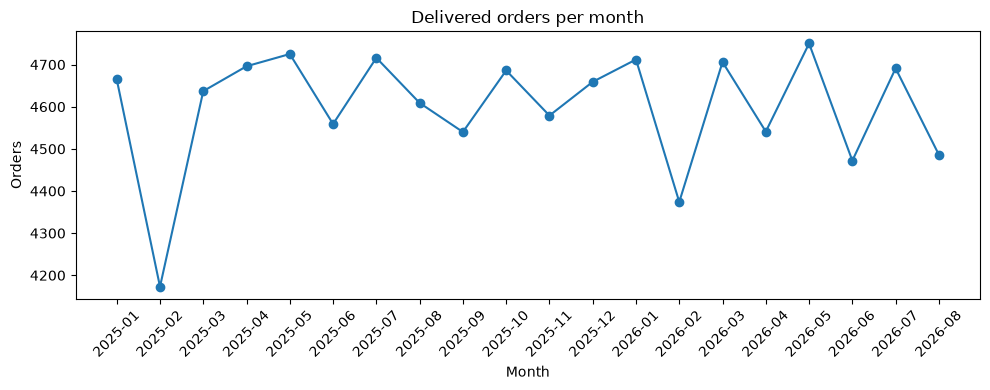

In [14]:
# grouping delivered orders by month: count of orders, revenue, profit
monthly = delivered.groupby("Order_Month").agg(
    orders=("Order_ID", "count"),
    revenue=("Platform_Revenue_INR", "sum"),
    profit=("Estimated_Profit_INR", "sum")
).reset_index()

print(monthly)

# line chart of orders by month
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(monthly["Order_Month"], monthly["orders"], marker="o")
plt.title("Delivered orders per month")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# counting how many days of data each month has
days = delivered.groupby("Order_Month")["Order_Date"].nunique()

monthly["days"] = monthly["Order_Month"].map(days)
monthly["orders_per_day"] = (monthly["orders"] / monthly["days"]).round(1)

print(monthly[["Order_Month", "orders", "days", "orders_per_day"]])

   Order_Month  orders  days  orders_per_day
0      2025-01    4665    31           150.5
1      2025-02    4173    28           149.0
2      2025-03    4637    31           149.6
3      2025-04    4696    30           156.5
4      2025-05    4725    31           152.4
5      2025-06    4559    30           152.0
6      2025-07    4716    31           152.1
7      2025-08    4609    31           148.7
8      2025-09    4540    30           151.3
9      2025-10    4686    31           151.2
10     2025-11    4579    30           152.6
11     2025-12    4659    31           150.3
12     2026-01    4712    31           152.0
13     2026-02    4374    28           156.2
14     2026-03    4706    31           151.8
15     2026-04    4541    30           151.4
16     2026-05    4750    31           153.2
17     2026-06    4472    30           149.1
18     2026-07    4691    31           151.3
19     2026-08    4486    30           149.5


In [16]:
# money and orders per city, delivered orders only
city = delivered.groupby("City").agg(
    orders=("Order_ID", "count"),
    revenue=("Platform_Revenue_INR", "sum"),
    profit=("Estimated_Profit_INR", "sum")
).reset_index()

# profit earned on an average order in each city
city["profit_per_order"] = (city["profit"] / city["orders"]).round(1)

city = city.sort_values("profit", ascending=False)
print(city)

             City  orders     revenue     profit  profit_per_order
9          Mumbai    7859  1333341.83  797737.55             101.5
1         Chennai    7652  1310786.73  792048.72             103.5
11           Pune    7675  1309005.05  789460.79             102.9
2           Delhi    7689  1311028.03  786057.81             102.2
10          Noida    7666  1302949.76  780956.97             101.9
5       Hyderabad    7583  1298778.00  780731.15             103.0
3   Greater Noida    7691  1305676.58  780673.02             101.5
8         Lucknow    7676  1301720.72  780185.28             101.6
6          Jaipur    7694  1298159.79  775384.18             100.8
0       Bengaluru    7632  1290822.23  773352.37             101.3
7         Kolkata    7532  1277595.76  765910.65             101.7
4        Gurugram    7627  1285949.39  764546.68             100.2


In [17]:
# profit per restaurant, delivered orders only
rest = delivered.groupby(["Restaurant", "Cuisine"]).agg(
    orders=("Order_ID", "count"),
    profit=("Estimated_Profit_INR", "sum")
).reset_index()

rest["profit_per_order"] = (rest["profit"] / rest["orders"]).round(1)
rest = rest.sort_values("profit", ascending=False)

print(rest.head(5))
print(rest.tail(5))

         Restaurant  Cuisine  orders     profit  profit_per_order
20          Popeyes  Chicken    3142  477580.06             152.0
15              KFC  Chicken    3133  464397.18             148.2
0           Bakingo   Bakery    3239  454211.22             140.2
5     Biryani Blues  Biryani    3290  440005.73             133.7
3   Behrouz Biryani  Biryani    3242  439194.49             135.5
     Restaurant       Cuisine  orders     profit  profit_per_order
10  Chinese Wok       Chinese    3088  218097.86              70.6
28    WOW! Momo         Momos    3244  165590.12              51.0
22  Sagar Ratna  South Indian    3119  159373.20              51.1
7   Burger King       Burgers    3166  144967.13              45.8
17   McDonald's       Burgers    3152  142795.51              45.3


In [18]:
# money and orders per city, delivered orders only
city = delivered.groupby("City").agg(
    orders=("Order_ID", "count"),
    revenue=("Platform_Revenue_INR", "sum"),
    profit=("Estimated_Profit_INR", "sum")
).reset_index()

# profit earned on an average order in each city
city["profit_per_order"] = (city["profit"] / city["orders"]).round(1)

city = city.sort_values("profit", ascending=False)
print(city)

             City  orders     revenue     profit  profit_per_order
9          Mumbai    7859  1333341.83  797737.55             101.5
1         Chennai    7652  1310786.73  792048.72             103.5
11           Pune    7675  1309005.05  789460.79             102.9
2           Delhi    7689  1311028.03  786057.81             102.2
10          Noida    7666  1302949.76  780956.97             101.9
5       Hyderabad    7583  1298778.00  780731.15             103.0
3   Greater Noida    7691  1305676.58  780673.02             101.5
8         Lucknow    7676  1301720.72  780185.28             101.6
6          Jaipur    7694  1298159.79  775384.18             100.8
0       Bengaluru    7632  1290822.23  773352.37             101.3
7         Kolkata    7532  1277595.76  765910.65             101.7
4        Gurugram    7627  1285949.39  764546.68             100.2


In [19]:
# averages per restaurant, to see what is different about the top and bottom ones
why = delivered.groupby("Restaurant").agg(
    avg_price=("Unit_Price_INR", "mean"),
    avg_discount=("Discount_INR", "mean"),
    avg_revenue=("Platform_Revenue_INR", "mean"),
    avg_cost=("Estimated_Cost_INR", "mean"),
    avg_profit=("Estimated_Profit_INR", "mean")
).round(1).sort_values("avg_profit", ascending=False)

print(why.head(3))
print(why.tail(3))

            avg_price  avg_discount  avg_revenue  avg_cost  avg_profit
Restaurant                                                            
Popeyes         377.9          50.1        212.3      60.3       152.0
KFC             376.6          51.5        209.5      61.2       148.2
Bakingo         349.6          46.1        202.6      62.4       140.2
             avg_price  avg_discount  avg_revenue  avg_cost  avg_profit
Restaurant                                                             
WOW! Momo        164.1          37.6        123.6      72.6        51.0
Burger King      153.9          35.5        117.7      72.0        45.8
McDonald's       154.1          37.0        117.4      72.1        45.3


In [20]:
# share of each order status inside each weather type (in %)
print(pd.crosstab(df_clean["Weather"], df_clean["Order_Status"], normalize="index").mul(100).round(1))

# average delivery time by weather, delivered orders only
print(delivered.groupby("Weather")["Delivery_Time_Min"].mean().round(1))

Order_Status  Cancelled  Delivered  Refunded
Weather                                     
Clear               5.0       91.9       3.1
Cloudy              4.7       92.4       2.9
Heavy Rain          5.1       92.0       2.9
Hot                 5.4       91.0       3.5
Rain                4.8       91.9       3.3
Weather
Clear         37.2
Cloudy        37.0
Heavy Rain    45.2
Hot           37.0
Rain          45.1
Name: Delivery_Time_Min, dtype: float64


In [21]:
# only delivered orders that have a rating
rated = delivered.dropna(subset=["Customer_Rating"])

# grouping delivery time into bands
bands = pd.cut(rated["Delivery_Time_Min"], [0, 30, 45, 60, 100],
               labels=["up to 30", "31-45", "46-60", "over 60"])

# order count and average rating in each band
print(rated.groupby(bands, observed=True)["Customer_Rating"].agg(["count", "mean"]).round(2))

                   count  mean
Delivery_Time_Min             
up to 30           17545  4.36
31-45              37352  4.36
46-60              18429  4.36
over 60             2045  4.35


In [22]:
# comparing the three promo groups, delivered orders only
promo = delivered.groupby("Promo_Status").agg(
    orders=("Order_ID", "count"),
    avg_order_value=("Final_Order_Value_INR", "mean"),
    avg_discount=("Discount_INR", "mean"),
    avg_profit=("Estimated_Profit_INR", "mean"),
    # share of orders that lost money, in %
    loss_rate=("Estimated_Profit_INR", lambda s: (s < 0).mean() * 100)
).round(1)

print(promo)

                   orders  avg_order_value  avg_discount  avg_profit  \
Promo_Status                                                           
Discount, no code   13393            478.3          79.7        83.2   
No discount         39260            562.2           0.0       126.5   
Promo code          39323            478.4          80.1        83.6   

                   loss_rate  
Promo_Status                  
Discount, no code        4.1  
No discount              0.0  
Promo code               3.9  


In [23]:
# comparing the basket before the discount is taken off
print(delivered.groupby("Promo_Status")[["Gross_Value_INR", "Quantity"]].mean().round(1))

                   Gross_Value_INR  Quantity
Promo_Status                                
Discount, no code            472.7       1.7
No discount                  472.9       1.7
Promo code                   473.5       1.7


In [24]:
# total discount given on delivered orders, and how it compares with profit
total_discount = delivered["Discount_INR"].sum()
discounted_orders = (delivered["Discount_INR"] > 0).sum()

print("Total discount given:", round(total_discount))
print("Orders with a discount:", discounted_orders)
print("Share of delivered orders with a discount %:", round(discounted_orders / len(delivered) * 100, 1))
print("Discount as % of estimated profit:", round(total_discount / profit * 100, 1))

Total discount given: 4217719
Orders with a discount: 52716
Share of delivered orders with a discount %: 57.3
Discount as % of estimated profit: 45.0


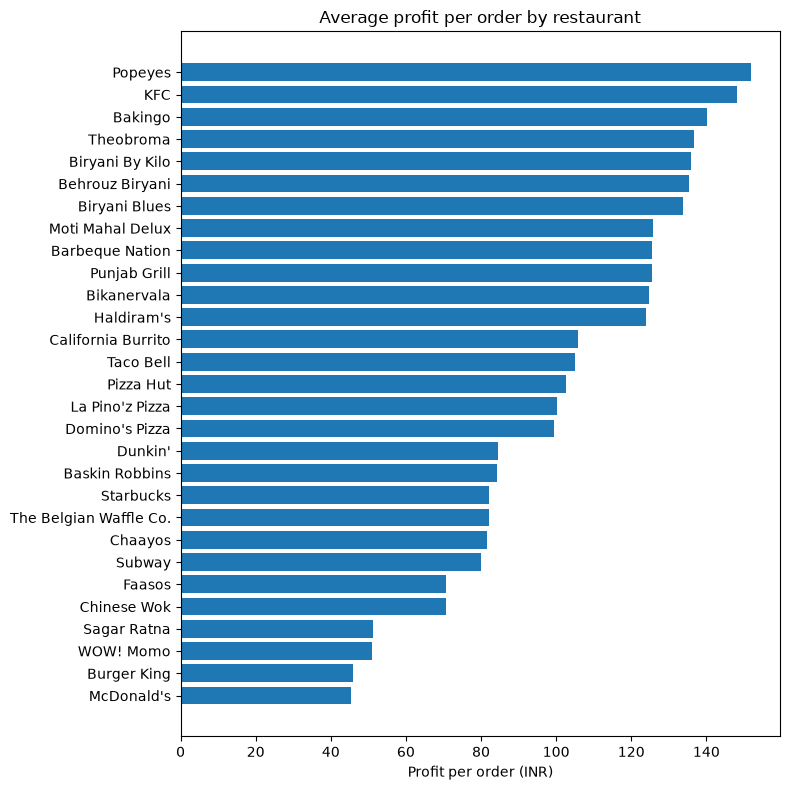

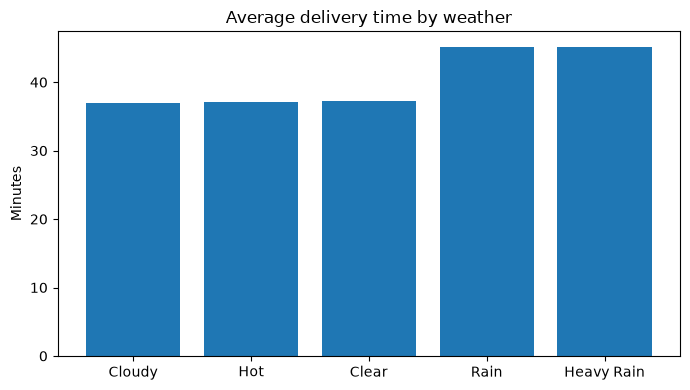

In [25]:
import matplotlib.pyplot as plt

# chart 1: profit per order for each restaurant
rest_sorted = rest.sort_values("profit_per_order")
plt.figure(figsize=(8, 8))
plt.barh(rest_sorted["Restaurant"], rest_sorted["profit_per_order"])
plt.title("Average profit per order by restaurant")
plt.xlabel("Profit per order (INR)")
plt.tight_layout()
plt.savefig("restaurant_profit_per_order.png", dpi=150)
plt.show()

# chart 2: delivery time by weather
weather = delivered.groupby("Weather")["Delivery_Time_Min"].mean().sort_values()
plt.figure(figsize=(7, 4))
plt.bar(weather.index, weather.values)
plt.title("Average delivery time by weather")
plt.ylabel("Minutes")
plt.tight_layout()
plt.savefig("delivery_time_by_weather.png", dpi=150)
plt.show()

In [26]:
# reading the saved cleaned file fresh, like SQL and Power BI will
final = pd.read_csv("greedy_uber_eats_100k_orders_cleaned.csv", parse_dates=["Order_Date"])

print("shape:", final.shape)
print("duplicate Order_IDs:", final["Order_ID"].duplicated().sum())
print("Order_Date type:", final["Order_Date"].dtype)
print("date range:", final["Order_Date"].min(), "to", final["Order_Date"].max())

# columns that still have blanks
missing = final.isna().sum()
print(missing[missing > 0])

# money check again on the saved file
calc = (final["Gross_Value_INR"] - final["Discount_INR"] + final["Packaging_Fee_INR"]
        + final["Delivery_Fee_INR"] + final["Tax_INR"])
print("final value mismatches:", ((calc - final["Final_Order_Value_INR"]).abs() > 0.05).sum())

# KPI check against baseline
d = final[final["Order_Status"] == "Delivered"]
print("delivered:", len(d), "profit:", round(d["Estimated_Profit_INR"].sum()))

shape: (100000, 38)
duplicate Order_IDs: 0
Order_Date type: datetime64[us]
date range: 2025-01-01 00:00:00 to 2026-08-30 00:00:00
Customer_Rating    24629
Promo_Code         57267
dtype: int64
final value mismatches: 0
delivered: 91976 profit: 9367045
